# Organic-layer thermal conductivity: old vs. new formulation

Both use the Ekici et al. (2014) / Porada et al. (2016) form `L = (Lsat - Lo) * Ke + Lo`, with `Ke = wtot / poros`.

- **old:** `Lsat = K_ORG**(1 - wtot) * K_WATER**wliq * K_ICE**wice`, multiplied by `Ke`, so moisture was counted twice
- **new:** `Lsat = K_ORG**(1 - poros) * K_WATER**(poros - wice) * K_ICE**wice`, the saturated value (current `pyAPES.soil.heat.thermal_conductivity`)

In [5]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))  # repo root, when run from debug_notebooks/

from pyAPES.soil.heat import thermal_conductivity
from pyAPES.utils.constants import K_ORG, K_WATER, K_ICE

LO = 0.05  # dry conductivity [W m-1 K-1]


def _as_arrays(poros, wliq, wice):
    return np.broadcast_arrays(*(np.atleast_1d(np.asarray(x, float)) for x in (poros, wliq, wice)))


def k_organic_old(poros, wliq, wice):
    poros, wliq, wice = _as_arrays(poros, wliq, wice)
    wtot = wliq + wice
    Ke = wtot / poros
    return K_ORG**(1.0 - wtot) * K_WATER**wliq * K_ICE**wice * Ke + (1.0 - Ke) * LO


def k_organic_new(poros, wliq, wice):
    """Calls the model function for a fully organic layer."""
    poros, wliq, wice = _as_arrays(poros, wliq, wice)
    comp = {'organic': np.ones_like(poros), 'sand': np.zeros_like(poros),
            'silt': np.zeros_like(poros), 'clay': np.zeros_like(poros)}
    return thermal_conductivity(poros, wliq, wice, comp, np.full_like(poros, np.nan))

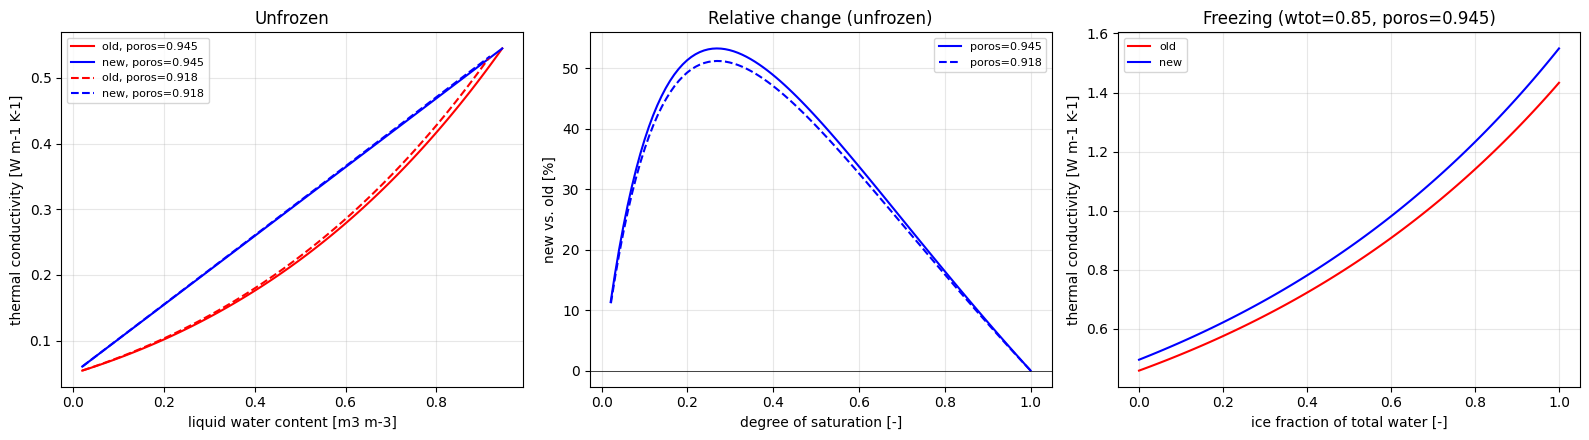

  wliq      old      new  change %
 0.945    0.545    0.545       0.0
 0.800    0.417    0.469      12.5
 0.600    0.279    0.364      30.7
 0.400    0.176    0.259      47.4
 0.200    0.102    0.155      52.0
 0.050    0.061    0.076      24.6


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1-2) unfrozen: conductivity vs. liquid water content
for poros, ls in ((0.945, '-'), (0.918, '--')):
    wliq = np.linspace(0.02, poros, 100)
    wice = np.zeros_like(wliq)
    k_old = k_organic_old(poros, wliq, wice)
    k_new = k_organic_new(poros, wliq, wice)
    axes[0].plot(wliq, k_old, 'r' + ls, label=f'old, poros={poros}')
    axes[0].plot(wliq, k_new, 'b' + ls, label=f'new, poros={poros}')
    axes[1].plot(wliq / poros, 100 * (k_new / k_old - 1), 'b' + ls, label=f'poros={poros}')

axes[0].set(xlabel='liquid water content [m3 m-3]', ylabel='thermal conductivity [W m-1 K-1]',
            title='Unfrozen')
axes[0].legend(fontsize=8)
axes[1].set(xlabel='degree of saturation [-]', ylabel='new vs. old [%]',
            title='Relative change (unfrozen)')
axes[1].axhline(0, color='k', lw=0.5)
axes[1].legend(fontsize=8)

# 3) frozen: fixed total water, increasing ice fraction
poros, wtot = 0.945, 0.85
ice_frac = np.linspace(0, 1, 100)
wice = wtot * ice_frac
wliq = wtot - wice
axes[2].plot(ice_frac, k_organic_old(poros, wliq, wice), 'r-', label='old')
axes[2].plot(ice_frac, k_organic_new(poros, wliq, wice), 'b-', label='new')
axes[2].set(xlabel='ice fraction of total water [-]', ylabel='thermal conductivity [W m-1 K-1]',
            title=f'Freezing (wtot={wtot}, poros={poros})')
axes[2].legend(fontsize=8)

for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

# table at a few representative water contents (poros = 0.945, unfrozen)
print(f"{'wliq':>6} {'old':>8} {'new':>8} {'change %':>9}")
for w in (0.945, 0.8, 0.6, 0.4, 0.2, 0.05):
    ko, kn = k_organic_old(0.945, w, 0.0)[0], k_organic_new(0.945, w, 0.0)[0]
    print(f"{w:6.3f} {ko:8.3f} {kn:8.3f} {100 * (kn / ko - 1):9.1f}")